# Clustering Major League Baseball Players

*Paul Hletko*

Baseball players are usually described by a few summary statistics (AVG, OBP, OPS, WAR), but modern tracking data gives a much richer picture of how players actually play. This project asks how the structure we find in MLB players depends on the clustering method and the representation used. Using Statcast and FanGraphs data, I will use feature sets for hitters (e.g., exit velocity, launch angle, sprint speed, plate discipline) and pitchers (e.g., pitch velocity, spin, movement, arsenal usage, release point) to cluster groups with k-means, Gaussian mixture models, and hierarchical clustering, and visualize the results with PCA, t-SNE, and diffusion maps. The comparison will focus on agreement between methods and interpretability, to separate structure that is robust from artifacts of the algorithm or of noise. Within each cluster, I will identify a representative player (the center of each cluster) and a “star” player (the player in the cluster with the most WAR in their career) to give each cluster a concrete interpretation for player development and career projections.


## Context

To comprehend the rest of this project, a basic understanding of the rules of baseball is recommended though omitted here. I will, however, define some vocabulary that will make up the feature set by which we cluster players.

1. Release point: The position on the baseball field from which the ball is released in a pitcher's throwing motion. May differ depending on what pitch is being thrown.
2. Plate Discipline: The tendency of batter's to behave rationally at the plate. This is determined by how often they swing at pitches outside of the zone and how often they strike out looking.
3. Exit Velocity and Launch Angle: These terms describe the trajectory at which a baseball is hit. Different hitters may tend to hit the ball faster or higher than others. Pitchers may induce weaker contact or more ground balls than their peers.
4. Pitch Velocity, Spin, Movement: These terms identify the way that a baseball is thrown by a pitcher. Movement may be vertical or horizontal and tends to depend on spin.
5. Arsenal Usage: This terms is relevant to how a pitcher uses the different pitches that they have in their arsenal. Some pitchers, like Jacob Misiorowski, may only utilize two or three pitches (typically a very fast four-seam fastball) whereas others may have a much larger arsenal meant to keep batters guessing as to what is coming next
6. BA: Batting Average, or what percentage of a batter's at bats end in a hit, excluding walks, hit by pitches, and sac flys
7. OBP, OPS: On Base Percentage (what percentage of at bats for a batter do they end up on base) and OBP Plus Slugging (Slugging is another stat similar to BA that weights doubles, triples, and HRs more highly)

## Data

Data for this project will include Statcast data. This tracks advanced metrics at all major league baseball games. The data has been used by all 30 MLB teams since the system was installed at every park in 2015. As such, all data will come from the period of 2016-2026. The data (and more high level stats such as BA, Pitch Count, etc) are all viewable on three main websites:

[Baseball Savant](https://baseballsavant.mlb.com/statcast_search), for statcast data

[Baseball Reference](https://www.baseball-reference.com/), for individual player career statistics, including awards

[Fangraphs](https://www.fangraphs.com/), for fan data analysis

This project uses a community built API for scraping data from these sites, called `pybaseball`. You can read more about this project at its [repository](https://github.com/jldbc/pybaseball).

Please see `pitchers.ipynb` and `batters.ipynb` for the creation of the csv files with player data that we use here.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


In [24]:
pitcher_df = pd.read_csv("pitcher_features.csv")
print(pitcher_df.shape)

# Identifiers and bookkeeping columns: keep for labeling, never feed to PCA
ID_COLS = [c for c in ["name", "IDfg", "mlbam_id"] if c in pitcher_df.columns]

# Columns that describe playing time or era rather than how a pitcher pitches.
# Kept in pitcher_df for filtering/plotting later, excluded from the feature matrix.
EXCLUDE = ID_COLS + [c for c in [
    "first_season", "last_season", "seasons_pitched",
    "IP_total", "TBF_total", "PA_total",
] if c in pitcher_df.columns]

pitcher_feature_cols = [c for c in pitcher_df.columns if c not in EXCLUDE]
X_pitcher = pitcher_df[pitcher_feature_cols].apply(pd.to_numeric, errors="coerce")
print(len(pitcher_feature_cols), "candidate features")

(1643, 39)
33 candidate features


In [25]:
MAX_MISSING = 0.20   # drop columns missing in more than 20% of pitchers

miss = X_pitcher.isna().mean().sort_values(ascending=False)
print(miss[miss > 0].head(20))

drop_cols = miss[miss > MAX_MISSING].index.tolist()
print("Dropping (too sparse):", drop_cols)
X_pitcher = X_pitcher.drop(columns=drop_cols)

# Remove constant columns, which break scaling
const = X_pitcher.columns[X_pitcher.nunique(dropna=True) <= 1].tolist()
X_pitcher = X_pitcher.drop(columns=const)

# Drop pitchers with too many missing features, then median-impute the rest
keep_rows = X_pitcher.isna().mean(axis=1) <= 0.20
print(f"Dropping {(~keep_rows).sum()} pitchers with >20% missing features")
X_pitcher = X_pitcher[keep_rows]
meta = pitcher_df.loc[X_pitcher.index, ID_COLS + [c for c in EXCLUDE if c not in ID_COLS]].copy()

X_pitcher = X_pitcher.fillna(X_pitcher.median())

whiff_percent_SC    0.999391
pitch_usage_SC      0.999391
whiff_percent_KN    0.998174
pitch_usage_FO      0.998174
pitch_usage_KN      0.998174
whiff_percent_FO    0.998174
whiff_percent_SV    0.991479
pitch_usage_SV      0.991479
whiff_percent_FS    0.927572
pitch_usage_FS      0.927572
whiff_percent_ST    0.855143
pitch_usage_ST      0.855143
whiff_percent_FC    0.757152
pitch_usage_FC      0.757152
pitch_usage_CU      0.650030
whiff_percent_CU    0.650030
pitch_usage_CH      0.589166
whiff_percent_CH    0.589166
pitch_usage_SI      0.514912
whiff_percent_SI    0.514912
dtype: float64
Dropping (too sparse): ['whiff_percent_SC', 'pitch_usage_SC', 'whiff_percent_KN', 'pitch_usage_FO', 'pitch_usage_KN', 'whiff_percent_FO', 'whiff_percent_SV', 'pitch_usage_SV', 'whiff_percent_FS', 'pitch_usage_FS', 'whiff_percent_ST', 'pitch_usage_ST', 'whiff_percent_FC', 'pitch_usage_FC', 'pitch_usage_CU', 'whiff_percent_CU', 'pitch_usage_CH', 'whiff_percent_CH', 'pitch_usage_SI', 'whiff_percent_SI', '

In [26]:
SKEW_THRESHOLD = 1.5

pitcher_skew = X_pitcher.skew()
to_log = [c for c in X_pitcher.columns if pitcher_skew[c] > SKEW_THRESHOLD and X_pitcher[c].min() >= 0]
print("log1p applied to:", to_log)

X_t_pitcher = X_pitcher.copy()
X_t_pitcher[to_log] = np.log1p(X_t_pitcher[to_log])

scaler = StandardScaler()
Xs = pd.DataFrame(scaler.fit_transform(X_t_pitcher), index=X_t_pitcher.index, columns=X_t_pitcher.columns)
print(Xs.describe().loc[["mean", "std"]].round(2).iloc[:, :5])

log1p applied to: ['xera']
      est_woba  est_ba  est_slg  xera  avg_hit_speed
mean      -0.0    -0.0     -0.0   0.0           -0.0
std        1.0     1.0      1.0   1.0            1.0


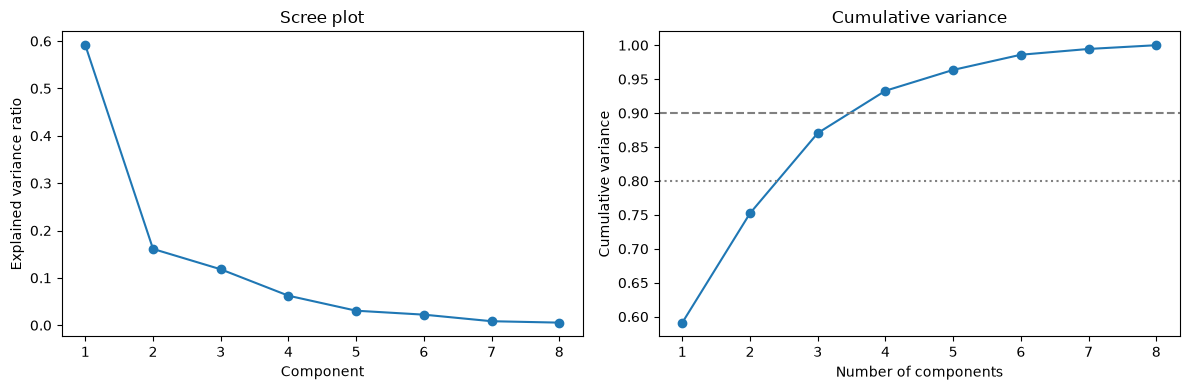

70% variance: 2 components
80% variance: 3 components
90% variance: 4 components
95% variance: 5 components
Eigenvalue > 1: 2 components


In [27]:
pca_full = PCA(random_state=0).fit(Xs)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, len(evr) + 1), evr, "o-")
ax[0].set(xlabel="Component", ylabel="Explained variance ratio", title="Scree plot")
ax[1].plot(range(1, len(cum) + 1), cum, "o-")
ax[1].axhline(0.90, ls="--", c="gray")
ax[1].axhline(0.80, ls=":", c="gray")
ax[1].set(xlabel="Number of components", ylabel="Cumulative variance", title="Cumulative variance")
plt.tight_layout()
plt.show()

for t in (0.70, 0.80, 0.90, 0.95):
    print(f"{t:.0%} variance: {np.searchsorted(cum, t) + 1} components")

# Kaiser criterion (eigenvalue > 1) as a second opinion
print("Eigenvalue > 1:", (pca_full.explained_variance_ > 1).sum(), "components")

In [28]:
N_COMPONENTS = 0.9   # or an int, e.g. 8

pca = PCA(n_components=N_COMPONENTS, random_state=0)
Z = pca.fit_transform(Xs)
k = Z.shape[1]
pc_names = [f"PC{i+1}" for i in range(k)]
print(f"Kept {k} components, {pca.explained_variance_ratio_.sum():.1%} of variance")

scores = pd.DataFrame(Z, index=Xs.index, columns=pc_names)
scores = pd.concat([meta.reset_index(drop=True), scores.reset_index(drop=True)], axis=1)

loadings = pd.DataFrame(pca.components_.T, index=Xs.columns, columns=pc_names)

# Top contributing features for the first few components
for pc in pc_names[:5]:
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(8)
    print(f"\n{pc} ({pca.explained_variance_ratio_[pc_names.index(pc)]:.1%})")
    print(top.round(3).to_string())

Kept 4 components, 93.3% of variance

PC1 (59.1%)
est_slg                  0.432
est_woba                 0.426
xera                     0.396
est_ba                   0.362
avg_hit_speed            0.321
ev95percent              0.299
brl_percent              0.296
anglesweetspotpercent    0.253

PC2 (16.1%)
ev95percent              0.568
avg_hit_speed            0.511
est_ba                  -0.381
brl_percent              0.340
xera                    -0.252
est_woba                -0.230
est_slg                 -0.161
anglesweetspotpercent   -0.116

PC3 (11.8%)
anglesweetspotpercent    0.706
brl_percent              0.511
est_ba                  -0.329
avg_hit_speed           -0.238
ev95percent             -0.237
est_woba                -0.105
xera                    -0.085
est_slg                  0.034

PC4 (6.2%)
anglesweetspotpercent    0.644
brl_percent             -0.588
avg_hit_speed            0.240
ev95percent              0.220
est_ba                   0.214
xera         

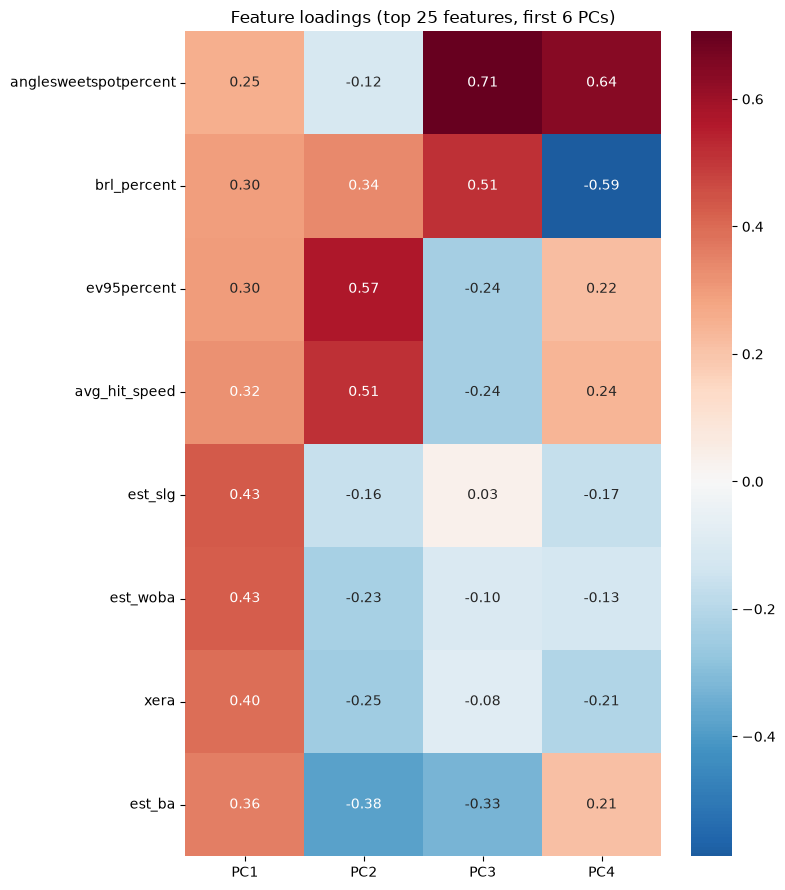

/var/folders/n2/r7dz7vnj4z30326gt_d7ybzr0000gn/T/ipykernel_33054/3871652405.py:13: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  sc = ax.scatter(scores["PC1"], scores["PC2"], c=pitcher_df.loc[meta.index, "GS_share"] if "GS_share" in pitcher_df else None,


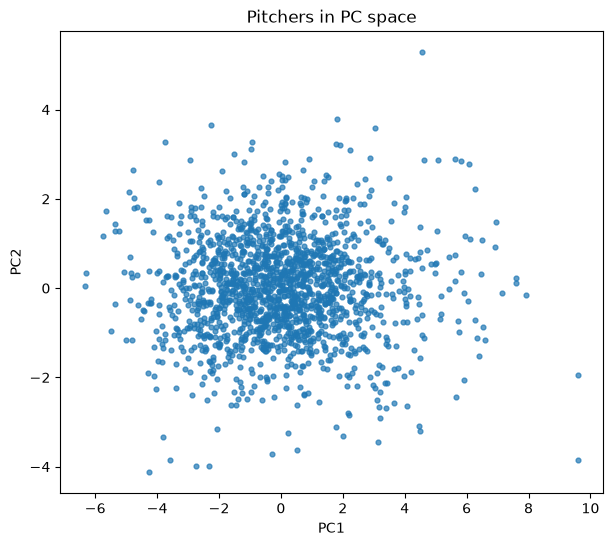

In [29]:
# Heatmap of loadings for the first components
import seaborn as sns
top_feats = loadings.iloc[:, :6].abs().max(axis=1).sort_values(ascending=False).head(25).index
plt.figure(figsize=(8, 9))
sns.heatmap(loadings.loc[top_feats, pc_names[:6]], cmap="RdBu_r", center=0, annot=True, fmt=".2f")
plt.title("Feature loadings (top 25 features, first 6 PCs)")
plt.tight_layout()
plt.show()

# PC1 vs PC2 scatter, colored by starter share if available
color = scores["GS_share"] if "GS_share" in scores else None
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(scores["PC1"], scores["PC2"], c=pitcher_df.loc[meta.index, "GS_share"] if "GS_share" in pitcher_df else None,
                cmap="viridis", s=12, alpha=0.7)
if "GS_share" in pitcher_df:
    plt.colorbar(sc, label="GS_share")
ax.set(xlabel="PC1", ylabel="PC2", title="Pitchers in PC space")
plt.show()

In [30]:
import joblib

scores.to_csv("pitcher_pca_scores.csv", index=False)
loadings.to_csv("pitcher_pca_loadings.csv")
joblib.dump({"scaler": scaler, "pca": pca, "columns": list(Xs.columns), "log_cols": to_log},
            "pitcher_pca_model.joblib")

['pitcher_pca_model.joblib']